# Лабораторная работа 1. Работа с типовыми наборами данных и различными моделями

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

Сгенерировать определённый тип данных и сравнить на нём три модели по варианту. Построить
графики, отобразить качество моделей, объяснить полученные результаты.

| Пункт задания | Вариант 20 |
|---|---|
| Данные | `make_circles(noise=0.2, factor=0.5, random_state=rs)` |
| Первая модель | линейная регрессия |
| Вторая модель | полиномиальная регрессия степени 5 |
| Третья модель | гребневая полиномиальная регрессия степени 5 при `alpha = 1.0` |
| Образец кода | пособие «Теория и практика машинного обучения», пункт «Регуляризация и сеть прямого распространения», стр. 228–236, листинги 61–74 |

## Ход работы

1. Сгенерировать данные, стандартизовать их и разбить на обучающую и тестовую выборки.
2. Обучить три модели варианта.
3. Оценить качество регрессионной и классификационной метриками.
4. Построить решающие поверхности моделей.
5. Измерить влияние регуляризации на коэффициенты.
6. Проверить устойчивость полученных результатов на нескольких случайных выборках.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_circles
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from mllab import RANDOM_STATE
from mllab.metrics import classification_threshold_accuracy
from mllab.plotting import annotate_score, class_legend, draw_points, draw_surface
from mllab.reporting import make_table


NOISE = 0.2
FACTOR = 0.5
DEGREE = 5
ALPHA = 1.0
TEST_SIZE = 0.4

# Общая шкала цвета для решающих поверхностей, симметричная относительно порога 0.5.
VMIN, VMAX = -0.5, 1.5

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)

## 1. Данные

Функция `make_circles` возвращает матрицу признаков размера 100 × 2 и вектор меток из нулей и
единиц. Объекты класса 0 расположены по окружности единичного радиуса, объекты класса 1 — по
концентрической окружности радиуса `factor`, то есть вдвое меньшего. Параметр `noise` задаёт
стандартное отклонение гауссова шума, который добавляется к обеим координатам каждой точки: при
значении 0.2 кольца размываются и частично перекрываются.

Генератор псевдослучайный, поэтому выборка полностью определяется начальным значением
`random_state`. В задании оно обозначено как `rs` и зафиксировано константой проекта
`RANDOM_STATE = 42`, чтобы результаты повторялись между запусками.

Размер выборки в задании не оговорён, поэтому взято значение по умолчанию, равное 100 объектам.

Перед обучением признаки стандартизованы: из каждого вычитается его среднее, разность делится на
стандартное отклонение. Оба признака получают нулевое среднее и единичную дисперсию и входят в
модель с одинаковым весом независимо от исходного масштаба. Затем выборка разделена на обучающую
и тестовую в пропорции 60/40, как в листинге 63 пособия. Тестовая часть при обучении не
используется: по ней проверяется, выучила ли модель общую закономерность или подстроилась под
конкретные точки.

In [2]:
X, y = make_circles(noise=NOISE, factor=FACTOR, random_state=RANDOM_STATE)
X = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

make_table(
    {
        "всего объектов": X.shape[0],
        "признаков": X.shape[1],
        "объектов класса 0 / 1": np.bincount(y),
        "обучающая выборка": X_train.shape[0],
        "тестовая выборка": X_test.shape[0],
        f"признаков после PolynomialFeatures({DEGREE})": PolynomialFeatures(DEGREE)
        .fit_transform(X_train)
        .shape[1],
    }
)

,значение
,
всего объектов,100
признаков,2
объектов класса 0 / 1,"[50, 50]"
обучающая выборка,60
тестовая выборка,40
признаков после PolynomialFeatures(5),21


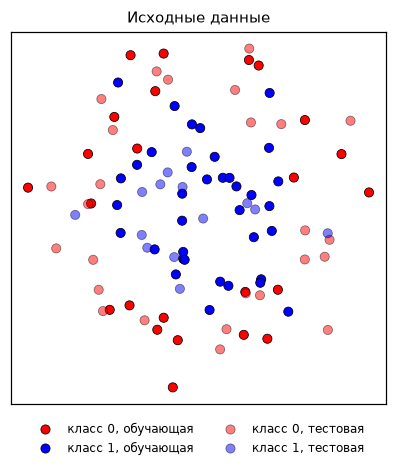

In [3]:
fig, ax = plt.subplots(figsize=(4.4, 4.4))
draw_points(ax, X_train, y_train)
draw_points(ax, X_test, y_test, alpha=0.5)
ax.set_title("Исходные данные")
ax.set_xticks(())
ax.set_yticks(())
class_legend(ax)
plt.show()

Объекты класса 1 собраны в центре, объекты класса 0 образуют вокруг них кольцо. Прямая, проведённая
по такому полю, в любом положении отсекает часть внешнего кольца вместе с центральным сгустком.
Линейная граница здесь неуместна, и для разделения классов модель должна зависеть от координат
нелинейно.

## 2. Модели

Регрессионная модель — это функция $f(x_1, x_2)$, которая по координатам объекта возвращает
вещественное число. Обучение подбирает её коэффициенты так, чтобы сумма квадратов отклонений
предсказаний от меток на обучающей выборке была наименьшей.

Линейная регрессия имеет вид

$$f(x_1, x_2) = w_0 + w_1 x_1 + w_2 x_2 .$$

График такой функции — наклонная плоскость, а множество точек, в которых она принимает значение
порога, — прямая линия. Форма границы задана самим видом функции и от данных не зависит, поэтому
концентрические кольца эта модель разделить не способна.

Полиномиальная регрессия применяет тот же линейный вид к расширенному набору признаков.
Преобразование `PolynomialFeatures(5)` заменяет пару $(x_1, x_2)$ набором одночленов
$x_1^{a} x_2^{b}$ со степенями $a + b \le 5$, всего 21 признак вместе со свободным членом:

$$f(x_1, x_2) = \sum_{a + b \le 5} w_{ab}\, x_1^{a} x_2^{b} .$$

По коэффициентам функция остаётся линейной и обучается тем же методом наименьших квадратов. В
исходных координатах её граница — кривая пятого порядка, которая способна замкнуться вокруг
центра.

Гребневая регрессия отличается от полиномиальной только видом минимизируемой величины: к сумме
квадратов ошибок добавляется штраф за величину коэффициентов,

$$\sum_i \bigl(y_i - f(x_i)\bigr)^2 + \alpha \sum_j w_j^2 .$$

Коэффициент $\alpha = 1.0$ задаёт вес штрафа: чем он больше, тем менее выгодны крупные
коэффициенты и тем более пологой выходит поверхность модели. Набор признаков тот же, что у
полиномиальной модели, поэтому сравнение этих двух моделей показывает вклад одного только штрафа.

| Модель | Состав | Назначение в эксперименте |
|---|---|---|
| Линейная | `LinearRegression` | базовый уровень качества линейной границы |
| Полином 5 | `PolynomialFeatures(5)` → `LinearRegression` | достаточность нелинейности степени 5 |
| Гребневая 5 | `PolynomialFeatures(5)` → `Ridge(alpha=1.0)` | вклад L2-регуляризации при той же гибкости |

Все три модели регрессионные, тогда как метки `make_circles` бинарные. Модель возвращает
вещественное число, поэтому для оценки качества применяются две метрики, описанные в п. 3.

In [4]:
def build_models() -> dict[str, object]:
    return {
        "Линейная": make_pipeline(LinearRegression()),
        f"Полином {DEGREE}": make_pipeline(PolynomialFeatures(DEGREE), LinearRegression()),
        f"Гребневая {DEGREE}": make_pipeline(PolynomialFeatures(DEGREE), Ridge(alpha=ALPHA)),
    }


fitted = {}
rows = []

for name, model in build_models().items():
    model.fit(X_train, y_train)
    fitted[name] = model
    rows.append(
        {
            "модель": name,
            "R² train": model.score(X_train, y_train),
            "R² test": model.score(X_test, y_test),
            "accuracy train": classification_threshold_accuracy(y_train, model.predict(X_train)),
            "accuracy test": classification_threshold_accuracy(y_test, model.predict(X_test)),
        }
    )

scores = pd.DataFrame(rows).set_index("модель").round(3)
scores

,R² train,R² test,accuracy train,accuracy test
модель,,,,
Линейная,0.009,-0.297,0.617,0.375
Полином 5,0.695,-0.198,0.900,0.725
Гребневая 5,0.684,-0.087,0.900,0.725


## 3. Метрики качества

Коэффициент детерминации вычисляется как

$$R^2 = 1 - \frac{\sum_i \bigl(y_i - f(x_i)\bigr)^2}{\sum_i \bigl(y_i - \bar{y}\bigr)^2},$$

где $\bar{y}$ — среднее значение меток. В числителе стоит ошибка модели, в знаменателе — ошибка
предсказания, которое всегда возвращает это среднее. Значение 1 отвечает точному попаданию, 0 —
совпадению с константным предсказанием, отрицательные значения — проигрышу константе. Метод
`model.score` возвращает именно эту величину, и её же минимизирует обучение.

Accuracy показывает долю объектов, класс которых определён верно. Модели возвращают вещественное
число, поэтому класс получается сравнением с порогом: объект относится к классу 1, если
предсказание превышает 0.5 (стр. 204 пособия). При равном числе объектов обоих классов случайное
угадывание даёт accuracy около 0.5.

R² оценивает точность приближения числа, accuracy — правильность отнесения к классу. Задача по
смыслу классификационная, а модели варианта регрессионные, поэтому приводятся обе величины.

R² на тестовой выборке отрицателен у всех трёх моделей: на новых данных они проигрывают
константе. Причина в соотношении размеров задачи — 60 обучающих объектов против 21 подбираемого
коэффициента. Модель с таким запасом свободы повторяет обучающие точки вместе с их шумом и плохо
переносится на остальные.

Accuracy линейной модели на тесте равна 0.375, что ниже уровня случайного угадывания. R² на
обучении у неё равен 0.009, то есть зависимость она практически не улавливает; предсказания
сосредоточены около 0.5. Сторону порога в этом случае определяют незначительные колебания, класс
назначается почти произвольно, поэтому значения 0.375 и 0.600 равновероятны.

## 4. Решающие поверхности

Чтобы увидеть построенную границу, область данных покрыта регулярной сеткой с шагом 0.02, в её
узлах вычислено значение модели и переведено в цвет. Получается карта ответов модели в каждой
точке плоскости признаков. Способ описан в пособии (листинги 68–71) и позволяет обойтись без
трёхмерных графиков. Поверх карты нанесена тестовая выборка, в правом нижнем углу подписана
accuracy на тесте.

Шкала цвета общая для всех трёх графиков и задана диапазоном [−0.5, 1.5], симметричным
относительно порога 0.5. Белый цвет соответствует порогу и показывает границу решения, красные
области модель относит к классу 0, синие — к классу 1. Там, где цвет точки расходится с цветом
фона под ней, модель ошибается. При настройках по умолчанию `contourf` нормирует цвет по каждому
графику отдельно, и тогда модели оказались бы несопоставимы между собой.

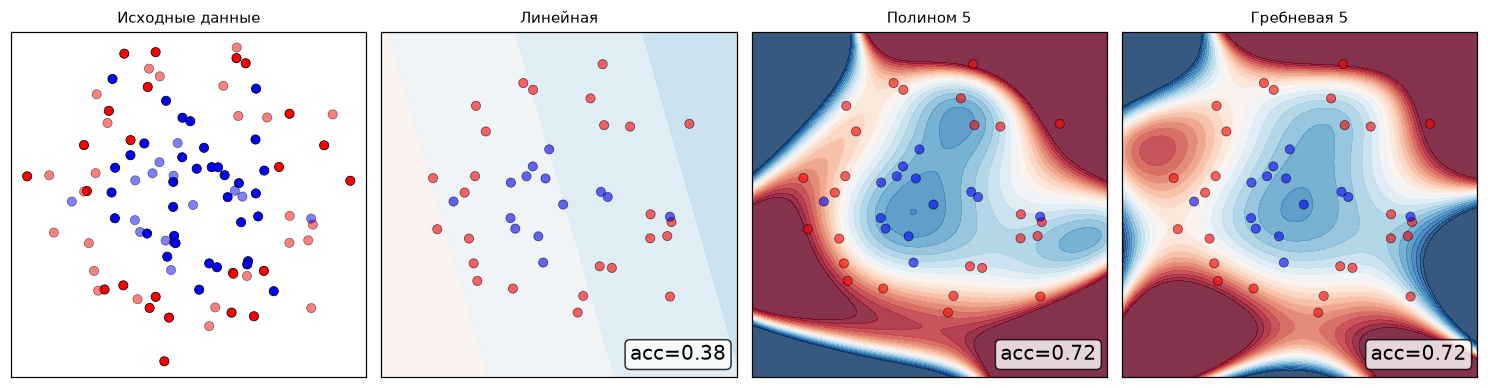

In [5]:
fig, axes = plt.subplots(1, len(fitted) + 1, figsize=(3.4 * (len(fitted) + 1), 3.6))

draw_points(axes[0], X_train, y_train)
draw_points(axes[0], X_test, y_test, alpha=0.5)
axes[0].set_title("Исходные данные")
axes[0].set_xticks(())
axes[0].set_yticks(())

for ax, (name, model) in zip(axes[1:], fitted.items(), strict=True):
    draw_surface(ax, model, X, vmin=VMIN, vmax=VMAX)
    draw_points(ax, X_test, y_test, alpha=0.6)
    annotate_score(ax, scores.loc[name, "accuracy test"], label="acc=")
    ax.set_title(name)

fig.tight_layout()
plt.show()

Поверхность линейной модели почти не окрашена: её значения по всему полю держатся около 0.5,
из-за чего граница решения занимает широкую бледную полосу. Это графическое объяснение accuracy
0.375. Слабый градиент направлен слева направо, то есть подобранная плоскость наклонена, но
наклоном внутреннее кольцо от внешнего не отделить.

У обеих полиномиальных моделей в центре виден замкнутый синий участок, повторяющий форму
внутренней окружности. Степени 5 достаточно, чтобы граница замкнулась, и предположение из п. 2
подтверждается.

Различие между полиномиальными моделями заметно по ширине переходной зоны. У гребневой модели
белая полоса вокруг центрального участка шире: её значения меняются медленнее, и вблизи границы
модель менее уверена. Так проявляется штраф за величину коэффициентов, размер которого измерен
ниже.

В углах обоих полиномиальных графиков, где обучающих точек нет, поверхность уходит в крайние
значения шкалы. Одночлены пятой степени быстро растут при удалении от начала координат, поэтому
за пределами области с данными предсказания теряют смысл. По метрикам качества этот эффект не
виден, так как тестовые точки лежат там же, где обучающие.

In [6]:
norms = []
for name in (f"Полином {DEGREE}", f"Гребневая {DEGREE}"):
    coefficients = fitted[name][-1].coef_
    norms.append(
        {
            "модель": name,
            "L2-норма коэффициентов": np.linalg.norm(coefficients),
            "макс. |коэффициент|": np.abs(coefficients).max(),
        }
    )

pd.DataFrame(norms).set_index("модель").round(3)

,L2-норма коэффициентов,макс. |коэффициент|
модель,,
Полином 5,0.955,0.538
Гребневая 5,0.592,0.343


## 5. Влияние регуляризации

Величину коэффициентов удобно оценивать их L2-нормой $\|w\|_2 = \sqrt{\sum_j w_j^2}$, то есть
длиной вектора коэффициентов. Эта же сумма квадратов входит в штраф гребневой регрессии.

Гребневая модель использует те же 21 признак, но её коэффициенты меньше: L2-норма снижается с
0.955 до 0.592, примерно на 38%. Accuracy на обучающей выборке у обеих моделей одинакова и равна
0.900, при этом R² на тесте у гребневой модели выше: −0.087 против −0.198.

Обе модели одинаково хорошо описывают обучающие точки, но гребневая достигает этого меньшими
коэффициентами и потому слабее реагирует на шум. На новых данных её предсказания точнее.

## 6. Устойчивость результатов

На одном разбиении полиномиальная и гребневая модели показали одинаковую accuracy, равную 0.725,
что не позволяет выбрать между ними. Тестовая выборка содержит 40 объектов, поэтому один верно
определённый объект меняет accuracy на 0.025, и устойчивое различие по одному разбиению от
случайного не отличить. Эксперимент повторён на 15 независимых выборках с изменением генерации
данных и разбиения.

In [7]:
SEEDS = 15

accuracy_by_seed: dict[str, list[float]] = {name: [] for name in build_models()}

for seed in range(SEEDS):
    X_seed, y_seed = make_circles(noise=NOISE, factor=FACTOR, random_state=seed)
    X_seed = StandardScaler().fit_transform(X_seed)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_seed, y_seed, test_size=TEST_SIZE, random_state=seed
    )
    for name, model in build_models().items():
        model.fit(X_tr, y_tr)
        accuracy_by_seed[name].append(classification_threshold_accuracy(y_te, model.predict(X_te)))

stability = (
    pd.DataFrame(
        [
            {
                "модель": name,
                "среднее": np.mean(values),
                "ст. отклонение": np.std(values),
                "минимум": np.min(values),
                "максимум": np.max(values),
            }
            for name, values in accuracy_by_seed.items()
        ]
    )
    .set_index("модель")
    .round(3)
)
stability

,среднее,ст. отклонение,минимум,максимум
модель,,,,
Линейная,0.437,0.078,0.325,0.600
Полином 5,0.812,0.086,0.650,0.975
Гребневая 5,0.843,0.072,0.675,0.975


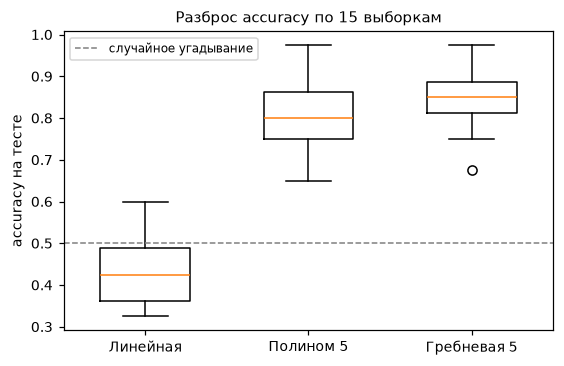

In [8]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.boxplot(accuracy_by_seed.values(), tick_labels=list(accuracy_by_seed), widths=0.55)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1, label="случайное угадывание")
ax.set_ylabel("accuracy на тесте")
ax.set_title(f"Разброс accuracy по {SEEDS} выборкам")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Средняя accuracy линейной модели составила 0.437 при стандартном отклонении 0.078 и разбросе от
0.325 до 0.600. Стандартное отклонение показывает типичный размах отклонения от среднего, и здесь
он таков, что результат свободно пересекает отметку 0.5 в обе стороны. Такое поведение отвечает
уровню случайного угадывания и подтверждает объяснение значения 0.375 из п. 3.

Полиномиальная модель дала 0.812 ± 0.086, гребневая — 0.843 ± 0.072. Гребневая превосходит
полиномиальную по среднему значению и одновременно устойчивее: её результат меньше зависит от
того, какая выборка попалась. На одном разбиении это различие не проявлялось.

## Выводы

1. Задача `make_circles` нелинейно разделима, поэтому линейная регрессия на ней неработоспособна:
   её accuracy статистически неотличима от случайного угадывания и составляет 0.437 при разбросе
   0.078.
2. Полиномиальное расширение признаков до степени 5 решает задачу. Решающая граница замыкается
   вокруг внутренней окружности, accuracy возрастает с 0.44 до 0.81.
3. Гребневая регуляризация при той же гибкости модели повышает среднюю accuracy до 0.843 и
   снижает разброс до 0.072, уменьшая L2-норму коэффициентов на 38%.
4. Отрицательный R² на тестовой выборке у всех моделей показывает недостаточный размер выборки:
   100 объектов для модели с 21 коэффициентом. Для классификационной задачи R² к тому же не
   является содержательной метрикой, что потребовало ввести accuracy.
5. Сравнения моделей по одному разбиению недостаточно: две полиномиальные модели показали
   одинаковую accuracy, и различие между ними выявилось только на серии из 15 выборок.

## Контрольные вопросы

**1. Зачем нужны типовые наборы данных?**

Типовые генераторы `make_circles`, `make_moons` и `make_classification` строят выборки по
известной формуле, поэтому свойства данных заданы заранее: известно, разделимы ли классы
линейно, какова размерность пространства и сколько добавлено шума.

Это позволяет проверять поведение моделей без реальных данных, поскольку результат заранее
интерпретируем: причина неудачи модели на `make_circles` известна точно. Сравнение моделей
проходит в контролируемых условиях, когда данные зафиксированы и меняется только модель. При
заданном `random_state` выборка воспроизводится на любой машине, что использовано в п. 6 для
повторения эксперимента 15 раз с управляемой случайностью.

**2. По каким критериям вы оценивали работу моделей?**

По двум метрикам, что вызвано двойственностью постановки: данные размечены бинарно, а модели
регрессионные.

Коэффициент детерминации R², вычисляемый методом `model.score`, сравнивает ошибку модели с
ошибкой константного предсказания и соответствует той величине, которую оптимизирует обучение.
Метрика вычислялась на обучающей и тестовой выборках, а разрыв между значениями показывает
степень переобучения.

Accuracy по порогу 0.5 отвечает на вопрос исходной задачи и показывает долю верно определённых
классов. Порог взят из пособия, стр. 204: объект относится к классу 1, когда предсказание
превышает 0.5.

Дополнительно применялись два критерия, не являющиеся метриками качества: L2-норма коэффициентов
для измерения эффекта регуляризации и среднее со стандартным отклонением по 15 выборкам для
проверки неслучайности различий между моделями.

**3. Какая модель показала лучшие результаты на вашем наборе данных?**

Гребневая полиномиальная регрессия степени 5 при `alpha = 1.0`. На отдельном разбиении она
сравнялась с полиномиальной моделью по accuracy, показав 0.725, и превзошла её по R² на тесте:
−0.087 против −0.198. На серии из 15 выборок различие выражено отчётливее: 0.843 ± 0.072 против
0.812 ± 0.086.

Линейная регрессия показала результат 0.437 и для данной задачи неприменима, поскольку
концентрические окружности не разделяются прямой линией.